# 모의고사 5회 | 생산 의사결정 풀이

자료 이해 → 고정 분석 조건 → 문항별 풀이 근거 → 실행 코드 → 실제 결과의 순서로 읽으십시오. 전체를 위에서 아래로 실행합니다. 변수의 산업적 의미는 각 절의 사전을 따르며, 공식 정답이나 실제 현장 성능을 뜻하지 않습니다.

실제 결과를 모은 [해설](해설.md)과 [자료 사전](자료안내.md)을 함께 사용하십시오.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.multitest import multipletests
from matplotlib import pyplot as plt
from IPython.display import display

HERE = Path.cwd()
REPO = next(
    p for p in [HERE] + list(HERE.parents) if (p / "src/Recipes/loader.py").exists()
)
sys.path.insert(0, str(REPO))
from src.Optimization.production_allocation import run_production_allocation
from src.Visualization.optimization.convergence import plot_convergence
from src.Visualization.regression.observed_predicted import plot_observed_predicted
from src.Visualization.qq.normal import plot_normal

quality = pd.read_csv(HERE / "data/quality.csv")
processes = pd.read_csv(HERE / "data/processes.csv")
cycles = pd.read_csv(HERE / "data/cycle_times.csv")
answers = []


def record(question, **values):
    answers.append(dict(question=question, **values))
    dest = HERE / "실행결과"
    dest.mkdir(exist_ok=True)
    (dest / "답안수치.json").write_text(
        json.dumps(answers, ensure_ascii=False, indent=2, allow_nan=False) + "\n"
    )

## 1. 생산 품질 예측과 검증 계획

**상황을 이해하기**

수율은 전체 생산품 중 양품이 차지하는 비율이며 배치는 함께 생산한 묶음입니다.

**관측 단위와 판단 목적**

투입 전에 아는 조건으로 최종 수율을 예측합니다. 설비를 몇 대 살지 결정하는 다음 과제와 데이터가 다릅니다. 지문에서 요구한 비교·예측·요약의 결과와 불확실성을 상황에 맞게 보고합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `quality.csv / id` | 독립 생산 배치 식별자 |
| `quality.csv / temperature` | 투입 전 온도(도) |
| `quality.csv / pressure` | 투입 전 압력(bar) |
| `quality.csv / speed` | 투입 전 속도(단위/분) |
| `quality.csv / yield` | 최종 수율(양품 비율, %) |

**고정 분석 조건**

스마트폰 조립공장은 투입 전에 측정한 temperature(도), pressure(bar), speed(단위/분)로 배치별 최종 yield(수율, %)를 예측하려 한다. id는 식별자이며 입력에서 제외한다. 각 행은 독립 배치의 창작 합성 자료다. 설비 배분 자료와는 별도의 예측 과제다. 전체 300행을 random_state=2026으로 학습 70%, 최종 평가 30% 분리하고, 학습 자료에서만 3-fold shuffled CV(random_state=2026)로 비교한다. temperature에 결측이 있으며 평균/중앙값 등의 추정은 각 학습 폴드 안에서 수행한다. 후보는 중앙값 대치·표준화·선형 회귀와 중앙값 대치·깊이 4의 랜덤포레스트(나무 60개, 시드 2026)로 사전 고정한다. 선택 기준은 원 수율 단위 RMSE다.

### 1-1

**문제 (10점)**

관측 단위·예측 시점·목표변수·입력 후보를 정리하고 결측 및 수치 분포를 탐색하시오. 식별자와 사후 수율을 입력에 포함할 때의 문제, 최종 평가 자료의 역할을 설명하시오.

**풀이 근거와 읽는 순서**

각 행은 투입 전 배치, id는 식별자이고 yield는 최종 목표다.

사후 수율을 입력으로 쓰면 타깃 누출이다.

결측 대치 통계량은 학습 자료에만 적합한다.

전체 자료의 기술 탐색은 수행하되 최종 평가값으로 전처리·후보를 변경하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [2]:
display(quality.describe())
display(quality.isna().sum())
record("1-1", n=len(quality), missing_temperature=int(quality.temperature.isna().sum()))

,id,temperature,pressure,speed,yield
count,300.000000,282.000000,300.000000,300.000000,300.000000
mean,150.500000,65.386507,3.983180,29.822917,85.077465
std,86.746758,5.158704,0.551042,5.764903,3.088407
min,1.000000,49.948436,2.404010,20.039356,77.134708
25%,75.750000,62.265318,3.607480,24.726177,82.770679
50%,150.500000,66.086632,4.015110,29.857955,85.479649
75%,225.250000,69.207822,4.318804,34.763637,87.664164
max,300.000000,77.252559,5.454550,39.998529,92.098217


id              0
temperature    18
pressure        0
speed           0
yield           0
dtype: int64

### 1-2

**문제 (10점)**

지정한 학습/평가 분할을 수행하고 각 CV 학습 폴드 안에서만 대치와 필요한 표준화를 적합하는 두 후보 파이프라인을 구성하시오. 원행 위치와 각 파이프라인의 전처리 적용 위치를 기록하시오.

**풀이 근거와 읽는 순서**

무작위 IID 학습/최종 평가 분할이며 표준화와 중앙값 대치를 Pipeline 안에 두므로 CV 폴드마다 다시 적합한다.

랜덤포레스트는 스케일에 의존하지 않아 대치만 적용한다.

시계열 배치에는 이 분할을 그대로 적용하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [3]:
train, test = train_test_split(
    np.arange(len(quality)), test_size=0.3, random_state=2026
)
X = quality[["temperature", "pressure", "speed"]]
y = quality["yield"]
models = {
    "linear": Pipeline(
        [
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("model", LinearRegression()),
        ]
    ),
    "forest": Pipeline(
        [
            ("impute", SimpleImputer(strategy="median")),
            (
                "model",
                RandomForestRegressor(
                    n_estimators=60, max_depth=4, random_state=2026, n_jobs=1
                ),
            ),
        ]
    ),
}
cv = KFold(3, shuffle=True, random_state=2026)
record("1-2", train_indices=train.tolist(), test_indices=test.tolist())
print("train/test:", len(train), len(test))

train/test: 210 90


### 1-3

**문제 (10점)**

같은 학습 폴드로 두 후보를 비교하여 평균·표준편차 RMSE를 제시하고 사전 기준에 따라 하나를 선택하시오. 최종 평가 자료로 전처리나 후보를 선택하지 않은 근거와 과적합의 가능성을 설명하시오.

**풀이 근거와 읽는 순서**

동일 폴드의 원 단위 RMSE가 작은 모형을 고른다.

후보별 CV 점수 차이는 이 실행에서의 비교이며 독립 유의성 검정으로 주장하지 않는다.

수많은 추가 탐색을 하면 CV 선택에도 과적합할 수 있다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [4]:
scores = {
    name: np.sqrt(
        -cross_val_score(
            model, X.iloc[train], y.iloc[train], cv=cv, scoring="neg_mean_squared_error"
        )
    )
    for name, model in models.items()
}
comparison = pd.DataFrame(
    [
        dict(model=name, cv_rmse=float(s.mean()), cv_std=float(s.std()))
        for name, s in scores.items()
    ]
)
display(comparison)
selected = min(scores, key=lambda name: scores[name].mean())
record("1-3", comparison=comparison.to_dict("records"), selected=selected)

,model,cv_rmse,cv_std
0,linear,2.813085,0.170378
1,forest,1.634216,0.035150


### 1-4

**문제 (10점)**

선택 후보를 전체 학습 자료로 적합한 뒤 최종 평가의 RMSE·MAE·R²와 관측-예측 그림을 제시하시오. 설명력과 실제 일반화 성능, 수율 예측과 생산량·비용 최적화의 차이 및 배포 전 확인 사항을 설명하시오.

**풀이 근거와 읽는 순서**

최종 평가를 한 번 계산한다.

예측 R²는 보류 평균을 기준으로 한 상대 오차로, 계수의 유효성이나 인과 효과를 증명하지 않는다.

예측 점수가 설비 수의 최적성·실제 생산량을 보장하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

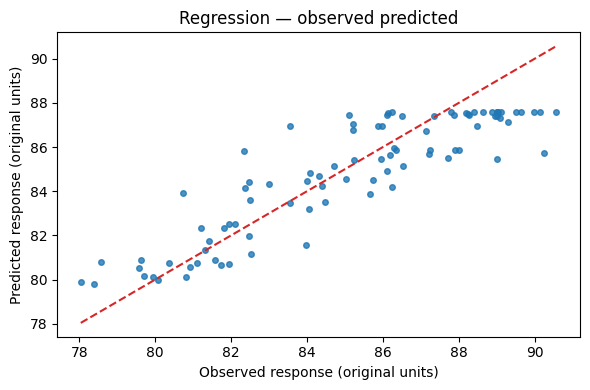

{'rmse': 1.5529411134315807, 'mae': 1.2699054603285005, 'r2': 0.7774846533718953}


In [5]:
fitted = models[selected].fit(X.iloc[train], y.iloc[train])
pred = fitted.predict(X.iloc[test])
metrics = dict(
    rmse=float(np.sqrt(mean_squared_error(y.iloc[test], pred))),
    mae=float(mean_absolute_error(y.iloc[test], pred)),
    r2=float(r2_score(y.iloc[test], pred)),
)
fig, ax = plt.subplots(figsize=(6, 4))
plot_observed_predicted(y.iloc[test], pred, ax=ax)
plt.tight_layout()
plt.show()
print(metrics)
record("1-4", **metrics)

## 2. 조립라인 설비 투자 의사결정

**상황을 이해하기**

조립→납땜→검사·포장은 차례로 거쳐야 하는 직렬 공정입니다. 같은 공정의 기계 여러 대는 병렬로 나누어 처리합니다.

**관측 단위와 판단 목적**

가장 느린 공정의 처리능력이 라인 전체의 상한입니다. 생산 가능량은 판매량·수요 보장이 아닙니다. 지문에서 요구한 비교·예측·요약의 결과와 불확실성을 상황에 맞게 보고합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `processes.csv / process` | 공정 순서 1=조립, 2=납땜, 3=검사·포장 |
| `processes.csv / minutes_per_unit` | 기계 한 대가 한 개를 처리하는 분 |
| `processes.csv / purchase_cost` | 구매비(만원/대) |
| `processes.csv / operating_cost` | 연간 운영비(만원/대) |

**고정 분석 조건**

세 공정은 어셈블리 → 납땜 → 검사·포장의 직렬 구조이며 각 공정 내 기계는 동일 성능으로 병렬 처리한다. 기계별 연간 작업시간은 하루 8시간, 주 5일, 연 50주다. 공정별 한 대의 처리시간은 각각 3·2·4분/개, 구매비는 5,000·7,000·4,000만원/대, 연간 운영비는 1,000·1,200·800만원/대다. 목표는 연간 50,000개 이상이며 각 공정의 기계 수는 1~10의 정수다. 첫해 구매비+연간 운영비 합을 최소화한다. 불량·고장·교체·대기·재고와 감가상각은 고려하지 않는다. 처리능력은 공정별 설비 수×연 가동분/처리분이며 라인 처리능력은 그 최솟값이다. 예산 500,000만원 같은 문장상의 예시는 이 기본 문제의 제약으로 사용하지 않는다. 모든 소문항은 이 조건을 공유한다.

### 2-1

**문제 (6점)**

결정변수·단위·목적함수·변수 경계·생산량 제약을 수식으로 정의하시오. 연간 가동분과 한 대 기준 공정별 처리능력을 계산하고 직렬 라인의 생산량을 합이나 평균으로 계산할 수 없는 이유를 설명하시오.

**풀이 근거와 읽는 순서**

N=(N1,N2,N3)는 정수다.

H=8×5×50×60=120,000분, Qj=HNj/tj, Q=min Qj≥50,000.

목적 C=6,000N1+8,200N2+4,800N3(만원).

세 직렬 공정은 같은 제품을 순서대로 처리하므로 능력을 합하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [6]:
H = 8 * 5 * 50 * 60
unit = processes.purchase_cost + processes.operating_cost
one = H / processes.minutes_per_unit
print(H, one.tolist())
record(
    "2-1", annual_minutes=H, one_machine_capacity=one.tolist(), unit_cost=unit.tolist()
)

120000 [40000.0, 60000.0, 30000.0]


### 2-2

**문제 (6점)**

초기 배치 (1,1,1)의 비용·처리능력·병목·목표 부족량을 구하시오. 처리능력 식으로 공정별 필요 최소 정수 대수를 유도하고 그 배치가 목표를 만족하는지 확인하시오.

**풀이 근거와 읽는 순서**

초기 비용 19,000만원, 생산능력 30,000개, 검사·포장 병목이며 부족 20,000개다.

각 공정 Nj≥ceil(50,000tj/H), 따라서 (2,1,2)이며 능력 (80,000,60,000,60,000)개다.

두 공정이 공동 병목이다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [7]:
required = np.ceil(50000 * processes.minutes_per_unit / H).astype(int)
capacity = required * one
print(required.tolist(), capacity.tolist())
record(
    "2-2",
    initial_cost=float(unit.sum()),
    initial_production=float(one.min()),
    shortfall=50000 - float(one.min()),
    minimum_required=required.tolist(),
    capacities=capacity.tolist(),
)

[2, 1, 2] [80000.0, 60000.0, 60000.0]


### 2-3

**문제 (8점)**

정수 유전자와 실행가능성 우선 선택을 사용하는 확률적 탐색을 구현하시오. 개체 수 80, 최대 120세대, 시드 1234, 교차율 0.8, 유전자별 변이율 0.15, 엘리트 2개를 사용하고 30세대 무개선 시 종료하시오. 원 목적값·제약 위반·실행가능 비율을 기록하고 하나의 ax에 목적값 경과를 그리시오. 실행불가능 후보를 정답으로 보고하지 마시오.

**풀이 근거와 읽는 순서**

정수형 표현·토너먼트·교차·변이·엘리트 보존을 별도 모듈에서 수행한다.

제약 만족 후보가 위반 후보보다 항상 앞서고 위반 후보끼리는 정규화 위반 합을 우선한다.

무개선 종료는 탐색 중지 규칙이며 최적성 증명이 아니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

   process  machines  minutes_per_unit  ...  operating_cost  total_cost  bottleneck
0        1         2               3.0  ...          2000.0     12000.0       False
1        2         1               2.0  ...          1200.0      8200.0        True
2        3         2               4.0  ...          1600.0      9600.0        True

[3 rows x 8 columns]
stall


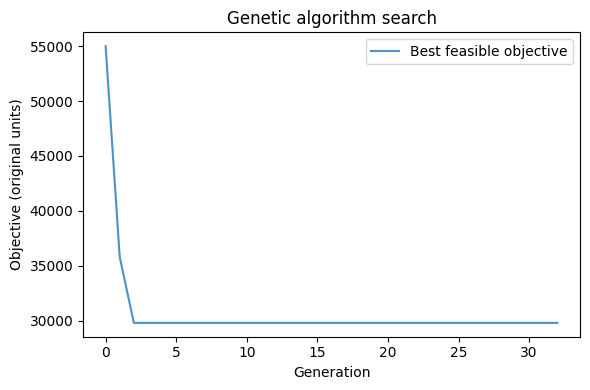

In [8]:
base_args = (
    processes.minutes_per_unit,
    processes.purchase_cost,
    processes.operating_cost,
)
allocation = run_production_allocation(*base_args)
print(allocation.process_table)
print(allocation.ga_result.stop_reason)
fig, ax = plt.subplots(figsize=(6, 4))
plot_convergence(allocation.ga_result, ax=ax)
plt.tight_layout()
plt.show()
record(
    "2-3",
    solution=(
        allocation.ga_result.best_solution.tolist()
        if allocation.ga_result.feasible
        else None
    ),
    cost=allocation.total_cost,
    production=allocation.annual_production,
    feasible=allocation.ga_result.feasible,
)

### 2-4

**문제 (8점)**

1~10대의 모든 조합을 독립 평가하여 최소 비용과 설비 배분을 구하시오. 앞 탐색 결과와 목적값 차이를 비교하고, 시드 0·1·2·3·4로 반복한 탐색의 실행가능률·최소/최대 비용·최적해 도달률을 보고하시오. 이번 반복 결과로 전역 최적성이 일반적으로 보장되는지 설명하시오.

**풀이 근거와 읽는 순서**

전수열거는 1,000개 조합을 모두 평가하므로 지정된 유한 문제의 전역 최적성을 확인한다.

최적 (2,1,2), 29,800만원이며 GA에서 얻은 해와 구분한다.

시드 다섯 번의 도달률은 이 문제·설정의 경험적 결과이지 다른 문제의 보장이 아니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [9]:
from itertools import product

exhaustive = [
    (float(np.array(n) @ unit), n)
    for n in product(range(1, 11), repeat=3)
    if min(np.array(n) * H / processes.minutes_per_unit) >= 50000
]
exact_cost, exact_solution = min(exhaustive)
runs = []
for seed in range(5):
    r = run_production_allocation(
        *base_args, overrides={"random_state": seed, "verify_exact": False}
    )
    runs.append(
        dict(
            seed=seed,
            feasible=r.ga_result.feasible,
            cost=r.total_cost,
            optimal=r.total_cost == exact_cost,
        )
    )
print(exact_cost, exact_solution)
display(pd.DataFrame(runs))
record(
    "2-4",
    exact_cost=exact_cost,
    exact_solution=list(exact_solution),
    ga_gap=allocation.objective_gap,
    runs=runs,
    feasible_rate=float(np.mean([r["feasible"] for r in runs])),
    optimal_rate=float(np.mean([r["optimal"] for r in runs])),
    minimum_cost=min(r["cost"] for r in runs if r["feasible"]),
    maximum_cost=max(r["cost"] for r in runs if r["feasible"]),
)

29800.0 (2, 1, 2)


,seed,feasible,cost,optimal
0,0,True,29800.0,True
1,1,True,29800.0,True
2,2,True,29800.0,True
3,3,True,29800.0,True
4,4,True,29800.0,True


### 2-5

**문제 (6점)**

같은 조건에서 목표 70,000개 및 90,000개로 각각 올릴 때 필요한 설비·비용·병목을 비교하시오. 목표 50,000개에서 비용 상한을 29,000만원으로 추가하면 가능한 해가 있는지 판단하고, 예산 부족과 탐색 실패를 구분하시오.

**풀이 근거와 읽는 순서**

70,000개에는 (2,2,3), 90,000개에는 (3,2,3)가 필요하다.

비용은 각각 42,800만원·48,800만원이다.

기본 최저 비용 29,800이 예산 29,000보다 크므로 예산 제약을 추가한 문제는 실행불가능하다.

GA 실패와 달리 전수검증으로 판단한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [10]:
scenarios = []
for demand in [70000.0, 90000.0]:
    r = run_production_allocation(*base_args, overrides={"target_production": demand})
    scenarios.append(
        dict(
            target=demand,
            solution=r.exact_solution.tolist(),
            cost=r.exact_cost,
            capacities=(r.exact_solution * H / processes.minutes_per_unit).tolist(),
        )
    )
impossible = run_production_allocation(*base_args, overrides={"budget": 29000.0})
print(scenarios, impossible.exact_status)
record("2-5", scenarios=scenarios, budget_status=impossible.exact_status)

[{'target': 70000.0, 'solution': [2, 2, 3], 'cost': 42800.0, 'capacities': [80000.0, 120000.0, 90000.0]}, {'target': 90000.0, 'solution': [3, 2, 3], 'cost': 48800.0, 'capacities': [120000.0, 120000.0, 90000.0]}] infeasible


### 2-6

**문제 (6점)**

최종 설비 배분·비용·여유 능력과 의사결정 근거를 보고하시오. 첫해 비용과 연간 반복 비용을 구분하고, 결정적 최적화에 p-value를 부여하지 않는 이유와 현장 적용에 추가할 불확실성·제약을 제안하시오.

**풀이 근거와 읽는 순서**

권고는 첫해 2억9,800만원, 설비 2·1·2대, 목표 대비 라인 여유 1만 개다.

구매비는 25,000만원, 운영비는 4,800만원이다.

결정적 최적화는 모집단 추론이 아니므로 p값이 없다.

고장·설비 가동률·서비스시간 변동·품질·작업자·현금흐름을 추가해야 실제 투자 판단에 가까워진다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [11]:
purchase = float(np.array(exact_solution) @ processes.purchase_cost)
operating = float(np.array(exact_solution) @ processes.operating_cost)
print("구매/연간 운영:", purchase, operating)
record(
    "2-6",
    purchase_cost=purchase,
    annual_operating_cost=operating,
    first_year_cost=purchase + operating,
    capacity_slack=allocation.annual_production - 50000,
)

구매/연간 운영: 25000.0 4800.0


## 3. 처리시간 개선안의 표본 근거

**상황을 이해하기**

처리시간은 한 개를 완성하는 데 걸리는 분이며 개선 방식에서 시간이 줄었는지 평가합니다.

**관측 단위와 판단 목적**

기존·개선 집단은 서로 다른 배치의 독립 표본입니다. 같은 batch 번호라도 전후 짝으로 연결하지 않습니다. 지문에서 요구한 비교·예측·요약의 결과와 불확실성을 상황에 맞게 보고합니다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `cycle_times.csv / process` | 비교할 공정 번호 |
| `cycle_times.csv / phase` | old=기존 방식, new=개선 방식 |
| `cycle_times.csv / batch` | 각 집단 안의 측정 배치 번호(전후 대응키 아님) |
| `cycle_times.csv / minutes` | 한 개 처리에 걸린 시간(분) |

**고정 분석 조건**

공정별 기존(old) 및 개선(new) 조건에서 서로 다른 독립 배치를 각각 30개 무작위 추출하여 단위 제품 처리시간 minutes를 측정했다고 가정한다. 행은 독립이고 전후 대응 자료가 아니다. 이 CSV는 검정 연습용 고정 합성이며 앞 공정 설계 상수와 구분한다. 공정별 처리시간은 정규 모집단 작업 가정을 사용하되 진단 한계를 보고한다. 분산은 알려져 있지 않으며 두 조건이 같다고 가정하지 않는다. 유의수준은 5%다. 검사·포장 공정(process=3)의 개선 후 평균이 이전보다 감소했는지의 단측 비교를 사전 지정한다. 별도로 개선 조건 세 공정 평균의 동시 상한을 가족 신뢰수준 95%로 구하고 이를 보수적인 처리시간 설계에 사용한다.

### 3-1

**문제 (5점)**

공정·조건별 표본 수·평균·표준편차를 제시하고 독립/대응 설계를 판단하시오. 공정이 다른 자료를 하나로 합쳐 평균 비교하면 어떤 문제가 있는지 설명하시오.

**풀이 근거와 읽는 순서**

새 배치에서 별도로 측정했으므로 독립 두 표본이다.

동일 배치 전후가 아니어서 대응 검정을 사용하지 않는다.

공정 처리시간 수준이 서로 달라 전체를 합치면 집단 구성 차이를 개선 효과와 혼동한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [12]:
summary = cycles.groupby(["process", "phase"]).minutes.agg(["size", "mean", "std"])
display(summary)
record("3-1", summary=summary.reset_index().to_dict("records"))

size      mean       std
process phase                          
1       new      30  2.874551  0.136089
        old      30  3.006561  0.097927
2       new      30  1.907688  0.109745
        old      30  1.983098  0.107915
3       new      30  3.785398  0.130755
        old      30  4.035439  0.185564

### 3-2

**문제 (5점)**

여섯 집단별 평균을 제거한 처리시간의 정규성 진단과 분포 그림을 제시하시오. 진단 가설·통계량·원 p-value와 여섯 검정의 Holm 보정 p-value·기각 여부를 보고하고, 비기각을 정규성의 증명으로 표현하지 마시오.

**풀이 근거와 읽는 순서**

각 집단의 중심화 자료에 Shapiro-Wilk 진단을 적용한다.

H0는 해당 모집단이 정규분포, H1은 비정규다.

평균 제거는 Shapiro 통계량에 영향을 주지 않는다.

여섯 진단의 Holm 보정으로 판단하고 비기각은 가정의 증명이 아니다.

QQ는 진단 그림이며 적합한 모수의 정식 독립 검정이 아니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

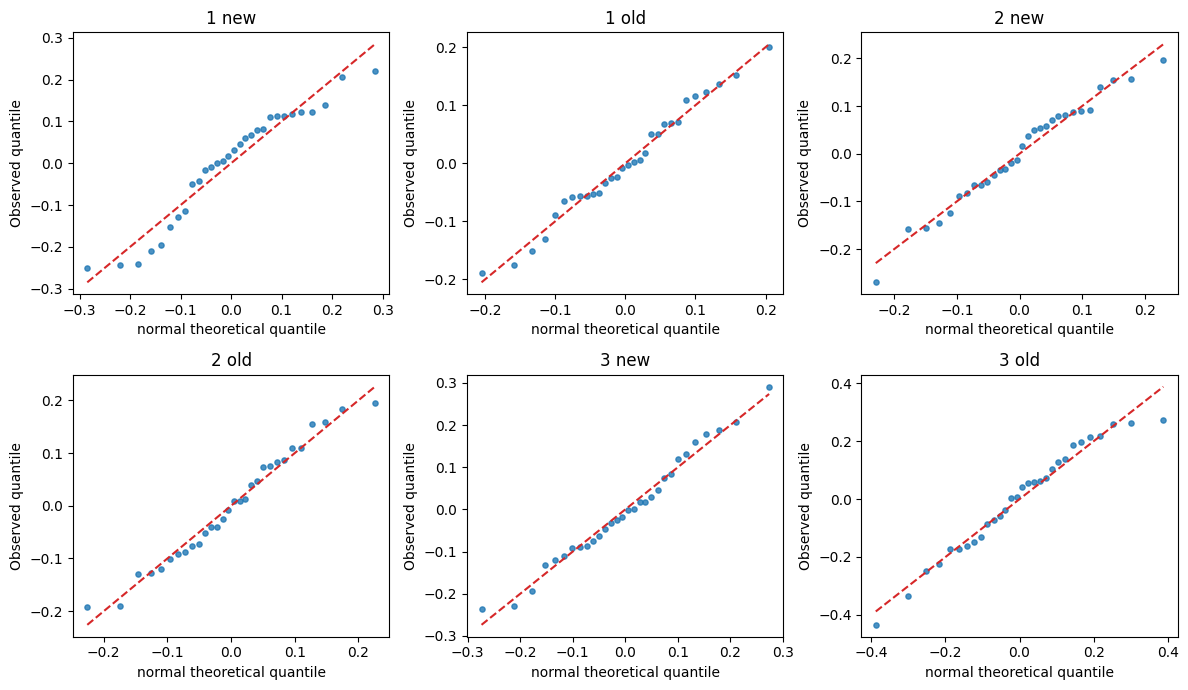

,process,phase,statistic,p_value,p_holm,reject_H0,H0,H1
0,1,new,0.931244,0.052990,0.317943,False,population is normal,population is not normal
1,1,old,0.980659,0.842808,1.000000,False,population is normal,population is not normal
2,2,new,0.975886,0.708835,1.000000,False,population is normal,population is not normal
3,2,old,0.972375,0.606005,1.000000,False,population is normal,population is not normal
4,3,new,0.982297,0.882790,1.000000,False,population is normal,population is not normal
5,3,old,0.966674,0.452631,1.000000,False,population is normal,population is not normal


In [13]:
normality = []
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, ((process, phase), part) in zip(
    axes.flat, cycles.groupby(["process", "phase"])
):
    residual = part.minutes - part.minutes.mean()
    stat, p = stats.shapiro(residual)
    normality.append(
        dict(process=int(process), phase=phase, statistic=float(stat), p_value=float(p))
    )
    plot_normal(
        residual,
        ax=ax,
        overrides={"fit_parameters": True, "title": str(process) + " " + phase},
    )
adjusted = multipletests([r["p_value"] for r in normality], method="holm")[1]
for r, p in zip(normality, adjusted):
    r.update(
        p_holm=float(p),
        reject_H0=bool(p < 0.05),
        H0="population is normal",
        H1="population is not normal",
    )
plt.tight_layout()
plt.show()
display(pd.DataFrame(normality))
record("3-2", tests=normality)

### 3-3

**문제 (5점)**

사전에 지정한 검사·포장 공정의 평균 감소 여부를 독립 표본에 맞는 방법으로 판단하시오. 방법 선정 근거·가정·귀무/대립가설·차이 방향·통계량·자유도·단측 p-value·기각 여부·업무 결론을 제시하시오. 다른 공정의 유리한 결과를 사후 선택하지 마시오.

**풀이 근거와 읽는 순서**

독립 정규 모집단 작업 가정에서 Welch 독립 두 표본 t 검정을 선택한다.

차이는 new-old이며 H0: μnew-μold≥0, H1:<0이다.

영가설 경계0에서 하측 p값을 계산한다.

등분산·분산 기지·대응을 가정하지 않는다.

평균 감소의 증거는 전체 라인의 실제 비용 감소나 인과 효과를 보장하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [14]:
old = cycles[(cycles.process == 3) & (cycles.phase == "old")].minutes.to_numpy()
new = cycles[(cycles.process == 3) & (cycles.phase == "new")].minutes.to_numpy()
a = new.var(ddof=1) / len(new)
b = old.var(ddof=1) / len(old)
difference = float(new.mean() - old.mean())
stat = difference / np.sqrt(a + b)
df = (a + b) ** 2 / (a * a / (len(new) - 1) + b * b / (len(old) - 1))
p = float(stats.t.cdf(stat, df))
report = dict(
    method="Welch one-sided",
    H0="mu_new-mu_old >= 0",
    H1="mu_new-mu_old < 0",
    difference=difference,
    statistic=float(stat),
    df=float(df),
    p_value=p,
    reject_H0=bool(p < 0.05),
    conclusion="평균 감소를 지지" if p < 0.05 else "평균 감소 근거 부족",
)
print(report)
record("3-3", **report)

{'method': 'Welch one-sided', 'H0': 'mu_new-mu_old >= 0', 'H1': 'mu_new-mu_old < 0', 'difference': -0.25004153021333186, 'statistic': -6.033079169728719, 'df': 52.10239205151343, 'p_value': 8.480696640778536e-08, 'reject_H0': True, 'conclusion': '평균 감소를 지지'}


### 3-4

**문제 (5점)**

개선 조건 세 공정 평균의 가족 신뢰수준 95% 단측 상한을 계산하고 이 상한을 처리시간으로 사용해 목표 50,000개 설비 배분·비용을 다시 구하시오. 보정 이유와 평균에 대한 신뢰상한이 개별 제품의 예측상한·실제 라인 신뢰도 보증과 다른 이유를 설명하시오.

**풀이 근거와 읽는 순서**

정규·독립 표본에서 각 평균의 단측 상한 mean+t(1-0.05/3,29)×s/√30을 사용한다.

Bonferroni로 세 상한의 가족 포함률이 적어도95%가 된다.

공정 간 독립은 Bonferroni에 필수는 아니다.

이 구간은 평균의 불확실성만 반영하며 제품 하나·고장·대기·연간 생산량 확률 보증이 아니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [15]:
upper = []
for process, part in cycles[cycles.phase == "new"].groupby("process"):
    bound = float(
        part.minutes.mean()
        + stats.t.ppf(1 - 0.05 / 3, len(part) - 1)
        * part.minutes.std(ddof=1)
        / np.sqrt(len(part))
    )
    upper.append(bound)
conservative = run_production_allocation(
    upper, processes.purchase_cost, processes.operating_cost
)
print(upper, conservative.exact_solution, conservative.exact_cost)
record(
    "3-4",
    mean_upper=upper,
    solution=conservative.exact_solution.tolist(),
    cost=conservative.exact_cost,
    family_confidence=0.95,
)

[2.930065350120009, 1.952456548718135, 3.838736877413063] [2 1 2] 29800.0
